In [1]:
%matplotlib inline
import os
import urllib.request
import matplotlib.pyplot as plt
import pandas as pd
import isoweek

Les données de l'incidence de la varicelle sont disponibles du site Web du [Réseau Sentinelles](http://www.sentiweb.fr/). Nous les récupérons sous forme d'un fichier en format CSV dont chaque ligne correspond à une semaine de la période demandée. Nous téléchargeons le jeu de données complet, qui commence en 1990 et se termine avec une semaine récente.

Comme pour le syndrome grippal, nous travaillons sur une **copie locale** des données: le fichier n'est téléchargé que s'il n'existe pas encore. L'URL d'origine est conservée ici pour la traçabilité. Le code de la maladie dans l'URL est `7` pour la varicelle.

In [2]:
data_url = "http://www.sentiweb.fr/datasets/incidence-PAY-7.csv"
data_file = "varicelle.csv"

Si le fichier local n'existe pas, nous téléchargeons les données depuis l'URL d'origine et nous les y déposons.

In [3]:
if not os.path.exists(data_file):
    urllib.request.urlretrieve(data_url, data_file)

Voici l'explication des colonnes données [sur le site d'origine](https://ns.sentiweb.fr/incidence/csv-schema-v1.json):

| Nom de colonne | Libellé de colonne                                                                                                                |
|----------------|-----------------------------------------------------------------------------------------------------------------------------------|
| week           | Semaine calendaire (ISO 8601)                                                                                                     |
| indicator      | Code de l'indicateur de surveillance                                                                                              |
| inc            | Estimation de l'incidence de consultations en nombre de cas                                                                       |
| inc_low        | Estimation de la borne inférieure de l'IC95% du nombre de cas de consultation                                                     |
| inc_up         | Estimation de la borne supérieure de l'IC95% du nombre de cas de consultation                                                     |
| inc100         | Estimation du taux d'incidence du nombre de cas de consultation (en cas pour 100,000 habitants)                                   |
| inc100_low     | Estimation de la borne inférieure de l'IC95% du taux d'incidence du nombre de cas de consultation (en cas pour 100,000 habitants) |
| inc100_up      | Estimation de la borne supérieure de l'IC95% du taux d'incidence du nombre de cas de consultation (en cas pour 100,000 habitants) |
| geo_insee      | Code de la zone géographique concernée (Code INSEE)                                                                               |
| geo_name       | Libellé de la zone géographique (ce libellé peut être modifié sans préavis)                                                       |

La première ligne du fichier CSV est un commentaire, que nous ignorons en précisant `skiprows=1`.

Nous lisons ensuite le fichier CSV local. Un tiret `-` marque une valeur manquante: nous le déclarons avec `na_values`, sinon les colonnes numériques seraient lues comme du texte.

In [5]:
raw_data = pd.read_csv(data_file, encoding='iso-8859-1', skiprows=1, na_values=['-'])
raw_data

,week,indicator,inc,inc_low,inc_up,inc100,inc100_low,inc100_up,geo_insee,geo_name
0,202643,7,4736,2131,7341,7,3,11,FR,France
1,202642,7,2238,886,3590,3,1,5,FR,France
2,202641,7,2590,1247,3933,4,2,6,FR,France
3,202640,7,1918,812,3024,3,1,5,FR,France
4,202639,7,1224,234,2214,2,1,3,FR,France
5,202638,7,592,0,1329,1,0,2,FR,France
6,202637,7,862,43,1681,1,0,2,FR,France
7,202636,7,975,167,1783,1,0,2,FR,France
8,202635,7,1130,186,2074,2,1,3,FR,France
9,202634,7,1682,301,3063,2,0,4,FR,France


Y a-t-il des points manquants dans ce jeu de données ? Nous le vérifions.

In [6]:
raw_data[raw_data.isnull().any(axis=1)]

,week,indicator,inc,inc_low,inc_up,inc100,inc100_low,inc100_up,geo_insee,geo_name


Nous éliminons les éventuels points manquants (s'il y en a), ce qui n'a pas d'impact fort sur notre analyse qui est assez simple.

In [7]:
data = raw_data.dropna().copy()
data

,week,indicator,inc,inc_low,inc_up,inc100,inc100_low,inc100_up,geo_insee,geo_name
0,202643,7,4736,2131,7341,7,3,11,FR,France
1,202642,7,2238,886,3590,3,1,5,FR,France
2,202641,7,2590,1247,3933,4,2,6,FR,France
3,202640,7,1918,812,3024,3,1,5,FR,France
4,202639,7,1224,234,2214,2,1,3,FR,France
5,202638,7,592,0,1329,1,0,2,FR,France
6,202637,7,862,43,1681,1,0,2,FR,France
7,202636,7,975,167,1783,1,0,2,FR,France
8,202635,7,1130,186,2074,2,1,3,FR,France
9,202634,7,1682,301,3063,2,0,4,FR,France


Nos données utilisent la même convention inhabituelle que pour le syndrome grippal: le numéro de
semaine est collé à l'année, donnant l'impression qu'il s'agit
d'un nombre entier. Nous réutilisons donc la même fonction de conversion, basée sur la bibliothèque `isoweek`, pour calculer une nouvelle colonne 'period'.

In [8]:
def convert_week(year_and_week_int):
    year_and_week_str = str(year_and_week_int)
    year = int(year_and_week_str[:4])
    week = int(year_and_week_str[4:])
    w = isoweek.Week(year, week)
    return pd.Period(w.day(0), 'W')

data['period'] = [convert_week(yw) for yw in data['week']]

Nous définissons les périodes d'observation comme index de notre jeu de données, puis nous trions les points dans le sens chronologique.

In [9]:
sorted_data = data.set_index('period').sort_index()

Nous vérifions la cohérence des données: entre la fin d'une période et le début de la période qui suit, la différence temporelle doit être nulle, ou au moins très faible (marge d'erreur d'une seconde). Toute semaine absente sera affichée.

In [10]:
periods = sorted_data.index
for p1, p2 in zip(periods[:-1], periods[1:]):
    delta = p2.to_timestamp() - p1.end_time
    if delta > pd.Timedelta('1s'):
        print(p1, p2)

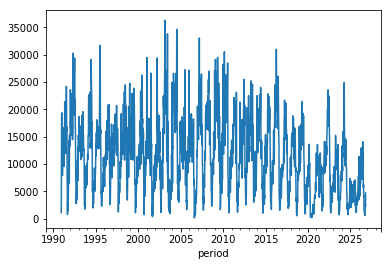

In [11]:
sorted_data['inc'].plot()

Un zoom sur les dernières années montre mieux la saisonnalité. Contrairement au syndrome grippal, dont les pics sont en hiver, les pics de varicelle se situent au printemps et le creux se trouve en été.

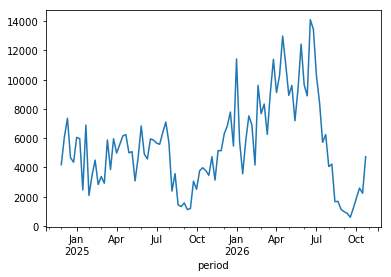

In [14]:
sorted_data['inc'][-100:].plot()

## Etude de l'incidence annuelle

Le pic de l'épidémie de varicelle se situe au printemps, donc **à l'intérieur** d'une année civile, contrairement au syndrome grippal. Mais les données commencent et se terminent en cours d'année, et le creux d'incidence se situe en été. Nous définissons donc la période de référence entre deux minima de l'incidence, du 1er septembre de l'année $N$ au 1er septembre de l'année $N+1$ (et non plus du 1er août).

Comme l'année ne comporte pas un nombre entier de semaines, à la place du 1er septembre de chaque année nous utilisons le premier jour de la semaine qui contient le 1er septembre. L'incidence étant très faible en été, cette modification ne risque pas de fausser nos conclusions.

Les données ne commencent pas au début d'une période: nous ne retenons que les périodes complètes. Le point de départ est calculé à partir des données, plutôt que fixé à la main comme pour le syndrome grippal, parce que cette série ne commence pas la même année. Nous nous arrêtons à la dernière période terminée.

In [15]:
first_week = sorted_data.index[0]
last_week = sorted_data.index[-1]

first_september_week = []
for y in range(first_week.year, last_week.year + 1):
    p = pd.Period(pd.Timestamp(y, 9, 1), 'W')
    # on garde les semaines du 1er septembre qui ouvrent ou ferment une période complète
    if p >= first_week and p <= last_week + 1:
        first_september_week.append(p)

print(first_september_week[0], '...', first_september_week[-1])

1991-08-26/1991-09-01 ... 2026-08-31/2026-09-06


In [16]:
year = []
yearly_incidence = []
for week1, week2 in zip(first_september_week[:-1],
                        first_september_week[1:]):
    one_year = sorted_data['inc'][week1:week2-1]
    assert abs(len(one_year)-52) < 2
    yearly_incidence.append(one_year.sum())
    year.append(week2.year)
yearly_incidence = pd.Series(data=yearly_incidence, index=year)

Voici les incidences annuelles

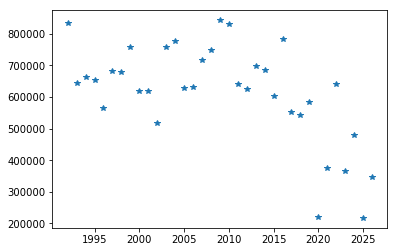

In [17]:
yearly_incidence.plot(style='*')

Une liste triée permet de plus facilement repérer les valeurs les plus élevées (à la fin) et les plus faibles (au début).

In [18]:
yearly_incidence.sort_values()

2025    217405
2020    221186
2026    347123
2023    366227
2021    376290
2024    479258
2002    516689
2018    542312
2017    551041
1996    564901
2019    584066
2015    604382
2000    617597
2001    619041
2012    624573
2005    628464
2006    632833
2022    641397
2011    642368
1993    643387
1995    652478
1994    661409
1998    677775
1997    683434
2014    685769
2013    698332
2007    717352
2008    749478
1999    756456
2003    758363
2004    777388
2016    782114
2010    829911
1992    832939
2009    842373
dtype: int64